# Visualization (Only predicted data)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import os
import pandas as pd
import numpy as np 
import re

In [ ]:
# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11

In [ ]:
base_dir = "/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Multinomial_Immigrants"

In [ ]:
belief_col = "Belief_opinion_on_what_should_be_done_with_illegal_immigrants_Symbol"

In [ ]:
# Define label mappings for demographic groups
label_mappings = {
    'sex_idx': {
        1: "Male",
        2: "Female"
    },
    'age_idx': {
        1: "18-24",
        2: "25-34",
        3: "35-44",
        4: "45-54",
        5: "55-64",
        6: "65+"
    },
    'eth_idx': {
        1: "White",
        2: "Black",
        3: "Hispanic",
        4: "Asian",
        5: "American Indian",
        6: "Other"
    },
    'income_idx': {
        1: "<$25k",
        2: "$25k-$50k",
        3: "$50k-$75k",
        4: "$75k-$100k",
        5: ">$100k"
    },
    'vote_idx': {
        1: "Did not vote",
        2: "Republican",
        3: "Democrat",
        4: "Libertarian",
        5: "Green",
        6: "Other"
    },
    'state_idx': {
        1: "AL", 2: "AK", 3: "AZ", 4: "AR", 5: "CA", 6: "CO", 7: "CT", 8: "DE", 9: "FL", 10: "GA",
        11: "HI", 12: "ID", 13: "IL", 14: "IN", 15: "IA", 16: "KS", 17: "KY", 18: "LA", 19: "ME", 20: "MD",
        21: "MA", 22: "MI", 23: "MN", 24: "MS", 25: "MO", 26: "MT", 27: "NE", 28: "NV", 29: "NH", 30: "NJ",
        31: "NM", 32: "NY", 33: "NC", 34: "ND", 35: "OH", 36: "OK", 37: "OR", 38: "PA", 39: "RI", 40: "SC",
        41: "SD", 42: "TN", 43: "TX", 44: "UT", 45: "VT", 46: "VA", 47: "WA", 48: "WV", 49: "WI", 50: "WY"
    }
}

def apply_labels(data, group_col):
    """
    Apply labels to group column values.
    
    Parameters:
    - data: DataFrame with group column
    - group_col: Name of the group column
    
    Returns:
    - DataFrame with renamed group values
    """
    data = data.copy()
    if group_col in label_mappings:
        data[group_col] = data[group_col].map(label_mappings[group_col]).fillna(data[group_col])
    return data

print("Label mappings loaded successfully!")

Label mappings loaded successfully!


In [ ]:
# Load consolidated time series data for each demographic group
def load_group_timeseries(base_dir, group_name):
    """Load time series predictions for a demographic group."""
    file_path = f"{base_dir}/group_{group_name}_category_probs_timeseries.csv"
    if os.path.exists(file_path):
        return pd.read_csv(file_path)
    else:
        print(f"Warning: {file_path} not found")
        return None

# Load all available group time series
groups_to_load = ['sex', 'age', 'eth', 'income', 'vote', 'state']
group_data = {}

for gname in groups_to_load:
    data = load_group_timeseries(base_dir, gname)
    if data is not None:
        group_data[gname] = data
        print(f"Loaded {gname}: {len(data)} rows, {data['time_window_start'].nunique()} time windows")

print(f"\nAvailable groups: {list(group_data.keys())}")

Loaded sex: 156 rows, 26 time windows
Loaded age: 468 rows, 26 time windows
Loaded eth: 468 rows, 26 time windows
Loaded income: 390 rows, 26 time windows
Loaded vote: 468 rows, 26 time windows
Loaded state: 3978 rows, 26 time windows

Available groups: ['sex', 'age', 'eth', 'income', 'vote', 'state']


In [ ]:
# Function: Plot category probabilities over time for specific groups
def plot_category_timeseries(data, group_col, group_values=None, figsize=(14, 8), 
                             title_prefix="", ncols=2, save_path=None):
    """
    Plot category probability time series for selected group values.
    
    Parameters:
    - data: DataFrame with columns [group_col, category, prob_mean, time_window_start]
    - group_col: Name of the grouping column
    - group_values: List of specific group values to plot (None = plot all)
    - figsize: Figure size
    - title_prefix: Prefix for plot title
    - ncols: Number of columns in subplot grid
    - save_path: Path to save the plot (e.g., 'plots/category_timeseries.png')
    """
    if data is None or len(data) == 0:
        print(f"No data available for {group_col}")
        return
    
    # Filter to specific group values if provided
    if group_values is not None:
        data = data[data[group_col].isin(group_values)].copy()
    
    # Apply labels if available
    data = apply_labels(data, group_col)
    
    unique_groups = sorted(data[group_col].unique())
    n_groups = len(unique_groups)
    
    if n_groups == 0:
        print(f"No groups found in {group_col}")
        return
    
    # Convert time windows to datetime for better plotting
    data['time_dt'] = pd.to_datetime(data['time_window_start'])
    
    # Create subplots
    nrows = int(np.ceil(n_groups / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    axes = axes.flatten()
    
    categories = sorted(data['category'].unique())
    colors = sns.color_palette("husl", len(categories))
    
    for idx, group_val in enumerate(unique_groups):
        ax = axes[idx]
        group_subset = data[data[group_col] == group_val]
        
        for cat_idx, cat in enumerate(categories):
            cat_data = group_subset[group_subset['category'] == cat].sort_values('time_dt')
            ax.plot(cat_data['time_dt'], cat_data['prob_mean'], 
                   marker='o', label=f'Category {cat}', color=colors[cat_idx], linewidth=2)
        
        ax.set_title(f"{title_prefix}{group_val}", fontsize=12, fontweight='bold')
        ax.set_xlabel('Time Window')
        ax.set_ylabel('Probability')
        ax.legend(loc='best', fontsize=9)
        ax.grid(True, alpha=0.3)
        ax.set_ylim([0, 1])
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
    
    # Hide unused subplots
    for idx in range(n_groups, len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    
    # Save if path provided
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Plot saved to: {save_path}")
    
    plt.show()

print("Function loaded: plot_category_timeseries()")


Function loaded: plot_category_timeseries()


In [ ]:
# Plot expected value time series with 95% credible intervals for a demographic group
def plot_expected_value_trends(base_dir, belief_col, group_name, group_values=None, 
                               figsize=(14, 6), ncols=2, save_path=None, gss_timeseries=None):
    
    # Load predictions from each time window
    time_window_dirs = [d for d in os.listdir(base_dir) if d.startswith(belief_col)]
    time_windows = sorted([d.replace(f"{belief_col}_", "").replace("_stan_output", "") 
                           for d in time_window_dirs])
    
    all_preds = []
    for window in time_windows:
        pred_file = f"{base_dir}/{belief_col}_{window}_stan_output/group_{group_name}_predictions.csv"
        if os.path.exists(pred_file):
            preds = pd.read_csv(pred_file)
            preds['time_window_start'] = window
            all_preds.append(preds)
    
    if not all_preds:
        print(f"No prediction files found for {group_name}")
        return
    
    data = pd.concat(all_preds, ignore_index=True)
    data['time_dt'] = pd.to_datetime(data['time_window_start'])
    
    # Determine group column name
    group_col = f"{group_name}_idx" if f"{group_name}_idx" in data.columns else \
                ('state_simple' if group_name == 'state' and 'state_simple' in data.columns else group_name)
    
    if group_col not in data.columns:
        print(f"Group column {group_col} not found")
        return
    
    # Filter to specific values if provided
    if group_values is not None:
        data = data[data[group_col].isin(group_values)].copy()
    
    # Apply labels if available
    data = apply_labels(data, group_col)
    
    unique_groups = sorted(data[group_col].unique())
    n_groups = len(unique_groups)
    
    if n_groups == 0:
        print(f"No groups to plot")
        return
    
    # Prepare GSS timeseries data if provided
    gss_data_to_plot = None
    if gss_timeseries is not None:
        gss_data_to_plot = gss_timeseries.copy()
        gss_data_to_plot['time_dt'] = pd.to_datetime(gss_data_to_plot['time_window_start'])
        # Apply same labels to GSS data
        gss_data_to_plot = apply_labels(gss_data_to_plot, group_name)
    
    # Automatically detect y-axis range from the data
    y_values = [data[['pred_mean', 'pred_lower']].min().min(), 
                data[['pred_mean', 'pred_upper']].max().max()]
    if gss_data_to_plot is not None:
        y_values.extend([gss_data_to_plot['lower'].min(), gss_data_to_plot['upper'].max()])
    y_min = np.floor(min(y_values))
    y_max = np.ceil(max(y_values))
    
    # Create subplots
    nrows = int(np.ceil(n_groups / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    axes = axes.flatten()
    
    for idx, group_val in enumerate(unique_groups):
        ax = axes[idx]
        group_data = data[data[group_col] == group_val].sort_values('time_dt')
        
        # Plot MrP mean with CI ribbon
        ax.plot(group_data['time_dt'], group_data['pred_mean'], 
               marker='o', linewidth=2.5, color='steelblue', label='MrP Mean')
        ax.fill_between(group_data['time_dt'], 
                        group_data['pred_lower'], 
                        group_data['pred_upper'],
                        alpha=0.3, color='steelblue', label='MrP 95% CI')
        
        # Plot GSS time series if available
        if gss_data_to_plot is not None:
            gss_group = gss_data_to_plot[gss_data_to_plot[group_name] == group_val].sort_values('time_dt')
            # Filter out small samples (n < 10)
            gss_group = gss_group[gss_group['n'] >= 10]
            if len(gss_group) > 0:
                ax.plot(gss_group['time_dt'], gss_group['mean'], 
                       marker='s', linewidth=2.5, color='darkorange', 
                       linestyle='--', label='GSS Mean', zorder=3)
                ax.fill_between(gss_group['time_dt'], 
                               gss_group['lower'], 
                               gss_group['upper'],
                               alpha=0.15, color='darkorange', 
                               label='GSS 95% CI', zorder=2)
        
        ax.set_title(f"{group_val}", fontsize=12, fontweight='bold')
        ax.set_xlabel('Time Window')
        ax.set_ylabel('Expected Belief Value')
        ax.set_ylim([y_min, y_max])
        ax.legend(loc='best', frameon=True, shadow=True)
        ax.grid(True, alpha=0.3)
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')

    
    # Hide unused subplots
    for idx in range(n_groups, len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle(f'Expected Value Trends: {group_name.capitalize()} Groups', 
                 fontsize=14, fontweight='bold', y=1.00)
    plt.tight_layout()
    
    # Save if path provided
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Plot saved to: {save_path}")
    
    plt.show()

print("Function loaded: plot_expected_value_trends()")

Function loaded: plot_expected_value_trends()


In [ ]:
# Create stacked area plots showing category probability evolution over time
def plot_category_stacked_area(data, group_col, group_values=None, figsize=(14, 8), ncols=2, save_path=None):
    
    if group_values is not None: # Filter to specific group values
        data = data[data[group_col].isin(group_values)].copy()
    
    data = apply_labels(data, group_col)
    
    unique_groups = sorted(data[group_col].unique())
    n_groups = len(unique_groups)
    
    if n_groups == 0:
        print(f"No groups found")
        return
    
    data['time_dt'] = pd.to_datetime(data['time_window_start'])
    
    # Create subplots
    nrows = int(np.ceil(n_groups / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    axes = axes.flatten()
    
    categories = sorted(data['category'].unique())
    colors = sns.color_palette("RdYlGn", len(categories))
    
    for idx, group_val in enumerate(unique_groups):
        ax = axes[idx]
        group_subset = data[data[group_col] == group_val]
        
        # Pivot to wide format for stacking
        pivot_data = group_subset.pivot(index='time_dt', columns='category', values='prob_mean')
        pivot_data = pivot_data.fillna(0).sort_index()
        
        # Stacked area plot
        ax.stackplot(pivot_data.index, 
                    *[pivot_data[cat] for cat in categories],
                    labels=[f'Cat {cat}' for cat in categories],
                    colors=colors, alpha=0.8)
        
        ax.set_title(f"{group_val}", fontsize=12, fontweight='bold')
        ax.set_xlabel('Time Window')
        ax.set_ylabel('Category Probability')
        ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
        ax.set_ylim([0, 1])
        ax.grid(True, alpha=0.3, axis='y')
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')
    
    # Hide unused subplots
    for idx in range(n_groups, len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    
    # Save if path provided
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Plot saved to: {save_path}")
    
    plt.show()

print("Function loaded: plot_category_stacked_area()")


Function loaded: plot_category_stacked_area()


In [ ]:
# Create output directory for plots
plots_dir = f"{base_dir}/visualizations"
os.makedirs(plots_dir, exist_ok=True)
print(f"Plots will be saved to: {plots_dir}\n")

Plots will be saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Multinomial_Immigrants/visualizations



Plots will be saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Multinomial_Immigrants/visualizations

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Multinomial_Immigrants/visualizations/expected_value_trends_sex.png


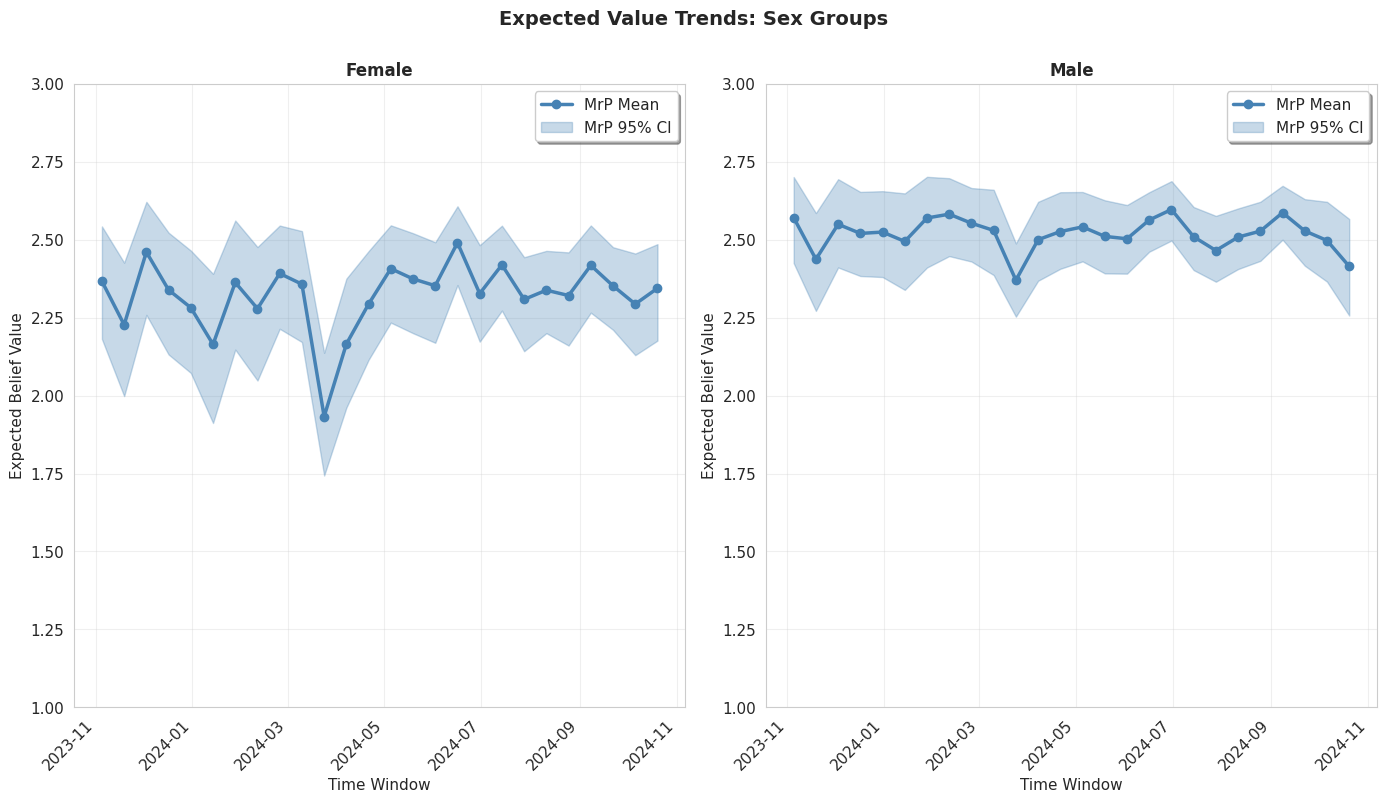

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Multinomial_Immigrants/visualizations/expected_value_trends_age.png


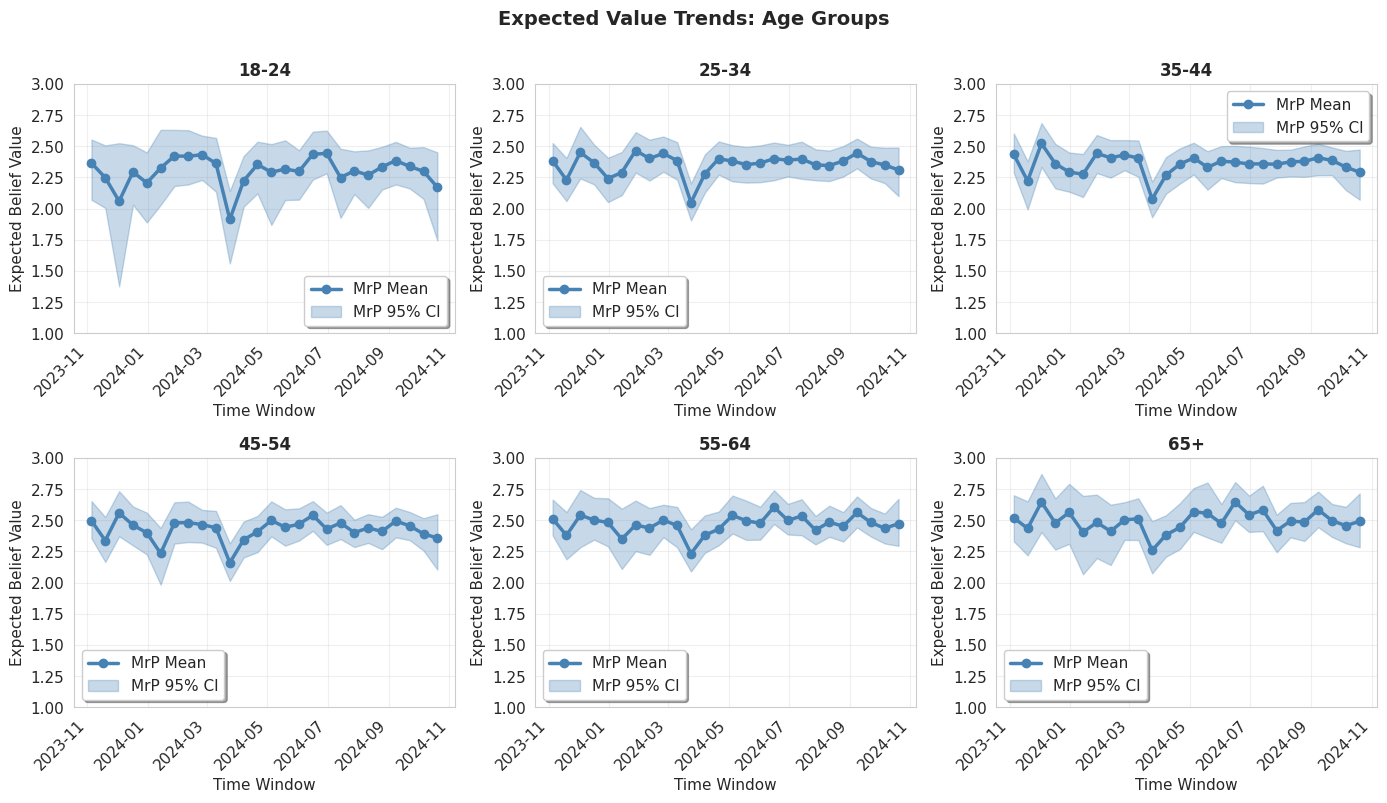

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Multinomial_Immigrants/visualizations/expected_value_trends_vote.png


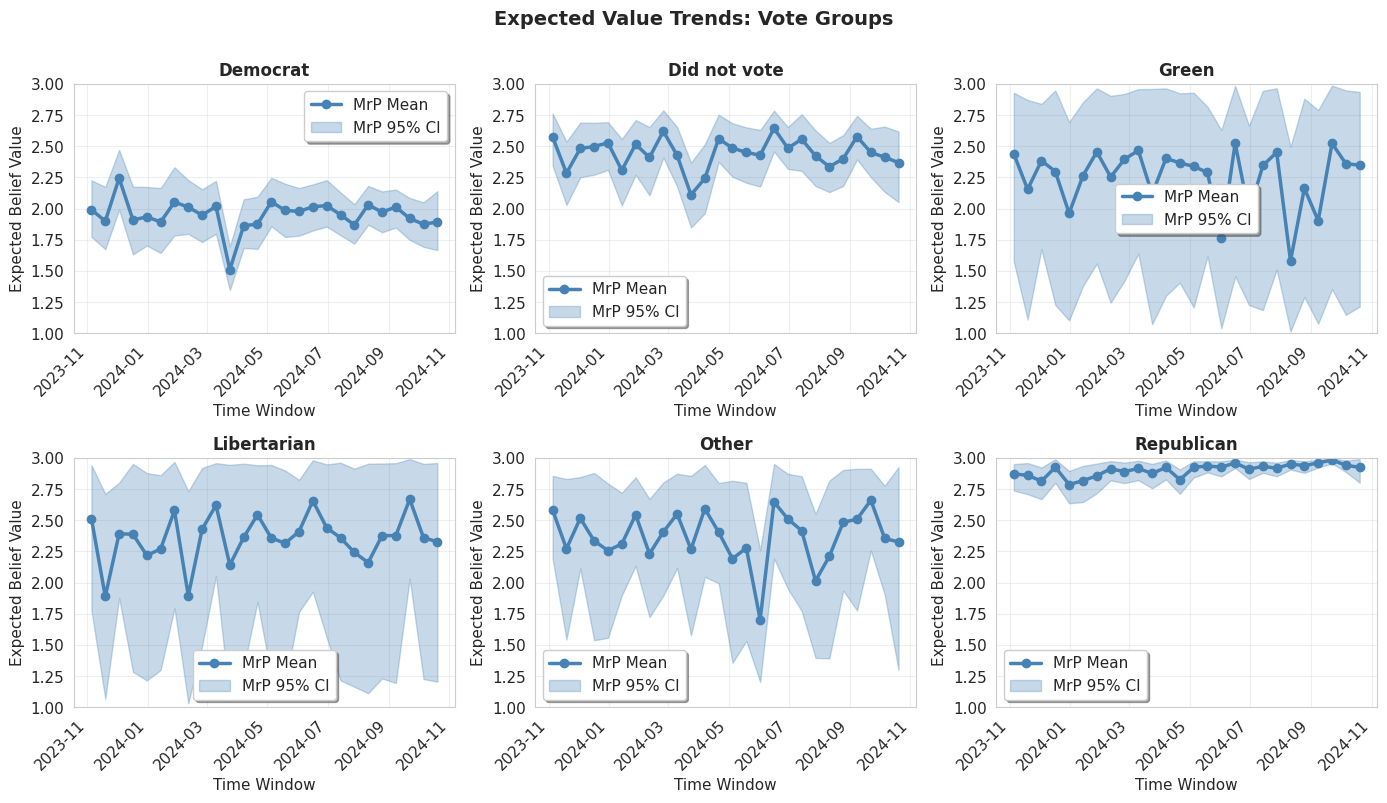

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Multinomial_Immigrants/visualizations/expected_value_trends_income_selected.png


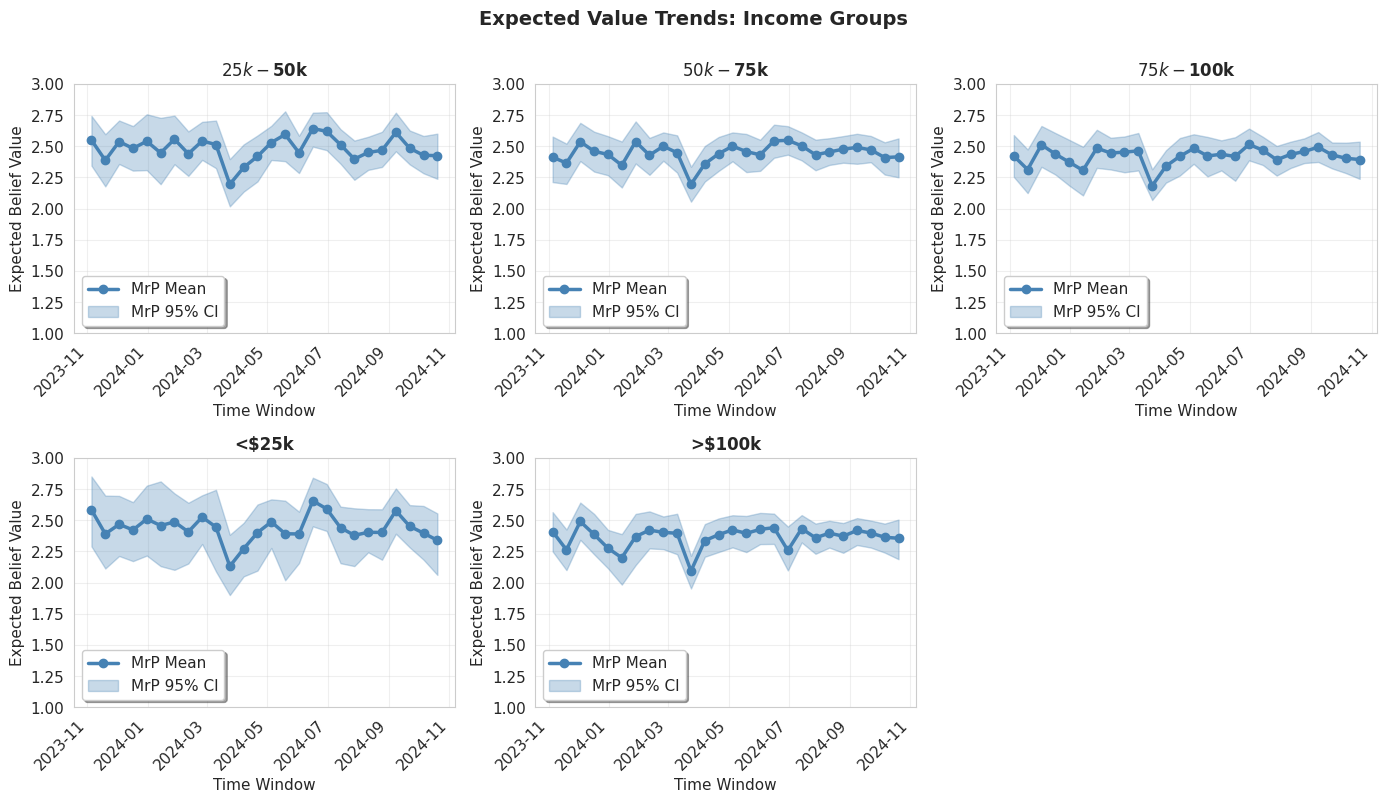


All plots saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Multinomial_Immigrants/visualizations


In [ ]:
# Create output directory for plots
plots_dir = f"{base_dir}/visualizations"
os.makedirs(plots_dir, exist_ok=True)
print(f"Plots will be saved to: {plots_dir}\n")

# Plot expected value trends by sex
plot_expected_value_trends(
    base_dir, 
    belief_col, 
    group_name='sex',
    figsize=(14, 8),
    ncols=2,
    save_path=f"{plots_dir}/expected_value_trends_sex.png"
)

# Plot expected value trends by age
plot_expected_value_trends(
    base_dir, 
    belief_col, 
    group_name='age',
    figsize=(14, 8),
    ncols=3,
    save_path=f"{plots_dir}/expected_value_trends_age.png"
)

# Plot expected value trends by vote
plot_expected_value_trends(
    base_dir, 
    belief_col, 
    group_name='vote',
    figsize=(14, 8),
    ncols=3,
    save_path=f"{plots_dir}/expected_value_trends_vote.png"
)

# Plot expected value trends by income (selected groups)
plot_expected_value_trends(
    base_dir,
    belief_col,
    group_name='income',
    figsize=(14, 8),
    ncols=3,
    save_path=f"{plots_dir}/expected_value_trends_income_selected.png"
)

print(f"\nAll plots saved to: {plots_dir}")

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Multinomial_Immigrants/visualizations/category_probabilities_sex.png


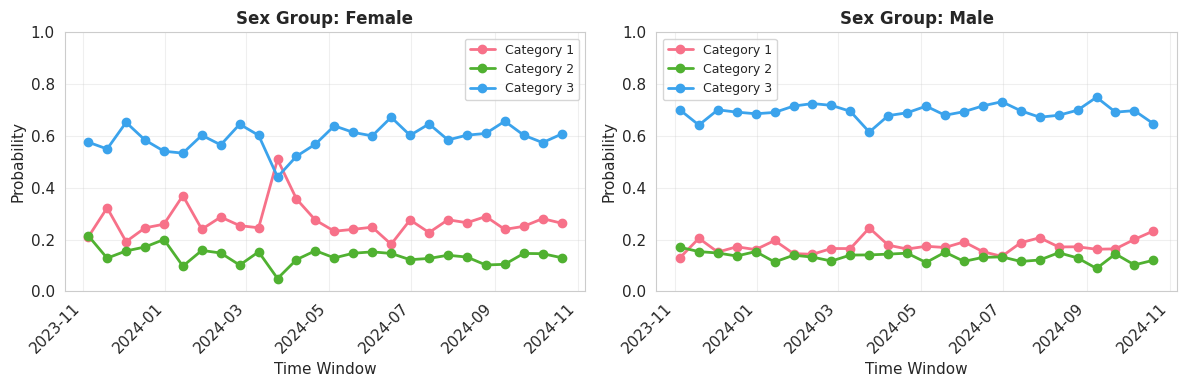

In [ ]:
# Category probabilities over time by sex
if 'sex' in group_data:
    plot_category_timeseries(
        group_data['sex'], 
        group_col='sex_idx',
        title_prefix="Sex Group: ",
        figsize=(12, 4),
        ncols=2,
        save_path=f"{plots_dir}/category_probabilities_sex.png"
    )

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Multinomial_Immigrants/visualizations/category_stacked_area_vote.png


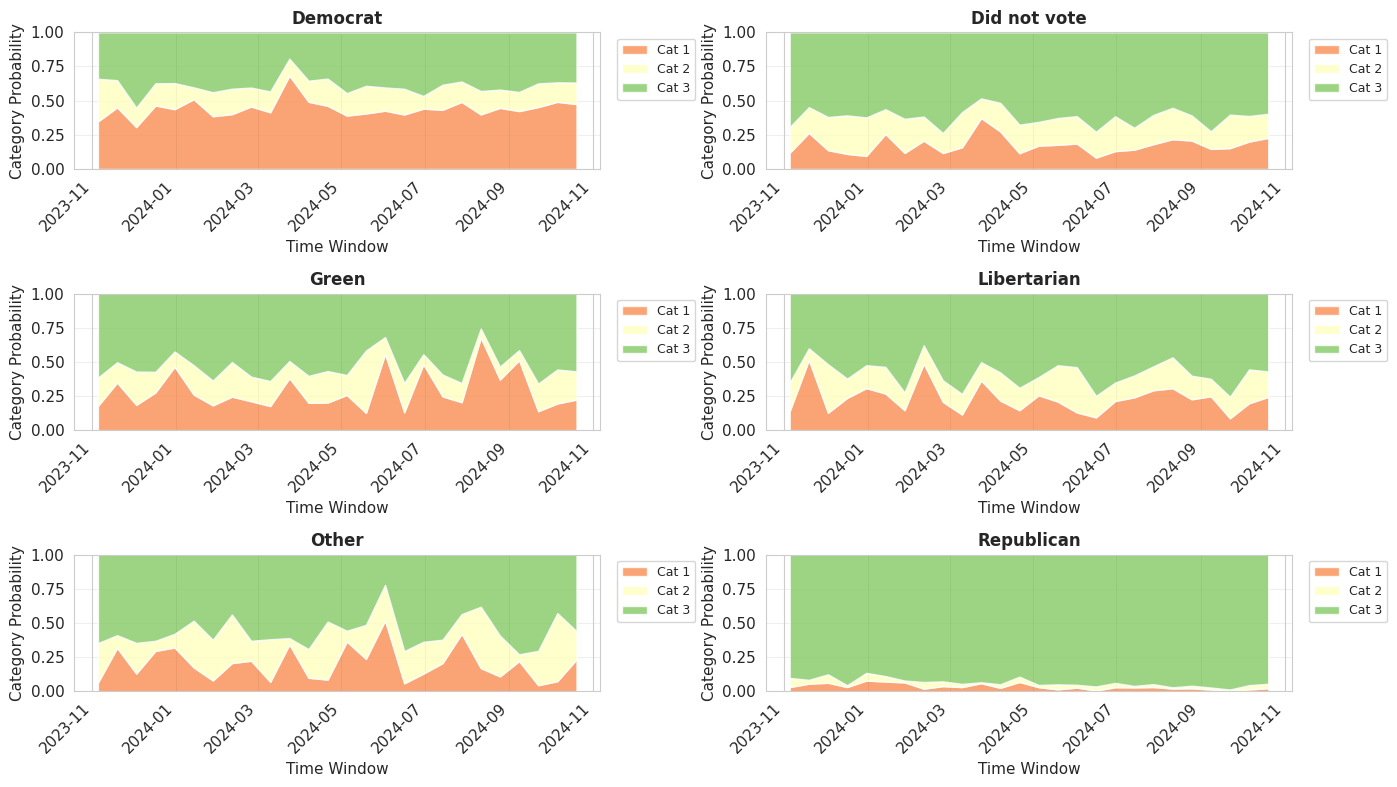

In [ ]:
# Stacked area plot for past vote groups
if 'vote' in group_data:
    plot_category_stacked_area(
        group_data['vote'],
        group_col='vote_idx',
        figsize=(14, 8),
        ncols=2,
        save_path=f"{plots_dir}/category_stacked_area_vote.png"
    )


# GSS Clean up

In [17]:
gss = pd.read_excel("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/num_immigrant/batch_0/result/GSS.xlsx", sheet_name="Data")
gss

,year,id_,age,educ,sex,race,partyid,letin1a,dateintv,ballot,income16
0,2024,1,33,4 years of college,MALE,Black,Not very strong democrat,Reduced a little,927,Ballot b,"$110,000 to $129,999"
1,2024,2,64,4 years of college,MALE,White,Strong democrat,Reduced a little,619,Ballot b,"$60,000 to $74,999"
2,2024,3,69,2 years of college,FEMALE,White,Strong democrat,Remain the same as it is,621,Ballot c,"$110,000 to $129,999"
3,2024,4,19,12th grade,MALE,Other,"Independent (neither, no response)",.d: Do not Know/Cannot Choose,814,Ballot a,"$150,000 to $169,999"
4,2024,5,70,1 year of college,FEMALE,White,"Independent (neither, no response)",Reduced a lot,921,Ballot c,"$60,000 to $74,999"
...,...,...,...,...,...,...,...,...,...,...,...
3304,2024,3305,84,8 or more years of college,MALE,White,Not very strong democrat,Increased a little,428,Ballot c,"$4,000 to $4,999"
3305,2024,3306,68,2 years of college,MALE,White,"Independent, close to democrat",Remain the same as it is,423,Ballot a,"$75,000 to $89,999"
3306,2024,3307,74,12th grade,FEMALE,White,"Independent (neither, no response)",Reduced a lot,730,Ballot a,"$50,000 to $59,999"
3307,2024,3308,51,8 or more years of college,FEMALE,White,"Independent, close to democrat",Remain the same as it is,1020,Ballot b,"$75,000 to $89,999"


In [20]:
# label clean up 

letin_map = {
    "Increased a lot": 1,
    "Increased a little": 2,
    "Remain the same as it is": 3,
    "Reduced a little": 4,
    "Reduced a lot": 5
}

gss["letin_num"] = gss["letin1a"].map(letin_map)
gss_clean = gss.dropna(subset=["letin_num"]).copy()


# Normalize sex values to title case (Male, Female)
gss_clean["sex"] = gss_clean["sex"].str.capitalize()

# Normalize age to age bins
gss_clean["age_num"] = pd.to_numeric(gss_clean["age"], errors="coerce")

age_bins = [18, 25, 35, 45, 55, 65, np.inf]
age_labels = [
    "18-24",
    "25-34",
    "35-44",
    "45-54",
    "55-64",
    "65+"
]

# Create age group variable
gss_clean["age"] = pd.cut(
    gss_clean["age_num"],
    bins=age_bins,
    labels=age_labels,
    right=False,      # include left endpoint, exclude right
    include_lowest=True
)

# Normalize income to bins
def extract_income_lower(income_str):
    if pd.isna(income_str):
        return np.nan
    # Remove $ and commas
    income_str = income_str.replace("$", "").replace(",", "")
    # Match first number
    match = re.match(r"(\d+)", income_str)
    if match:
        return float(match.group(1))
    return np.nan

gss_clean = gss_clean.copy()
gss_clean["income_num"] = gss_clean["income16"].apply(extract_income_lower)
income_bins = [0, 25000, 50000, 75000, 100000, np.inf]
income_labels = [
    "<$25k",
    "$25k-$50k",
    "$50k-$75k",
    "$75k-$100k",
    ">$100k"
]
gss_clean.loc[:, "income"] = pd.cut(
    gss_clean["income_num"],
    bins=income_bins,
    labels=income_labels,
    right=False,
    include_lowest=True
)

# Normalize past vote to simplified categories
vote_align_map = {
    "Strong democrat": "Democrat",      
    "Not very strong democrat": "Democrat",
    "Independent, close to democrat": "Democrat",  
    "Independent (neither, no response)": np.nan,
    "Independent, close to republican": np.nan,
    "Not very strong republican": "Republican",     
    "Strong republican": "Republican",
    "Other party with this past vote data": "Republican"
}

gss_clean.loc[:, "vote"] = gss_clean["partyid"].map(vote_align_map)
gss_clean

,year,id_,age,educ,sex,race,partyid,letin1a,dateintv,ballot,income16,letin_num,age_num,income_num,income,vote
0,2024,1,25-34,4 years of college,Male,Black,Not very strong democrat,Reduced a little,927,Ballot b,"$110,000 to $129,999",4.0,33.0,110000.0,>$100k,Democrat
1,2024,2,55-64,4 years of college,Male,White,Strong democrat,Reduced a little,619,Ballot b,"$60,000 to $74,999",4.0,64.0,60000.0,$50k-$75k,Democrat
2,2024,3,65+,2 years of college,Female,White,Strong democrat,Remain the same as it is,621,Ballot c,"$110,000 to $129,999",3.0,69.0,110000.0,>$100k,Democrat
4,2024,5,65+,1 year of college,Female,White,"Independent (neither, no response)",Reduced a lot,921,Ballot c,"$60,000 to $74,999",5.0,70.0,60000.0,$50k-$75k,NaN
5,2024,6,45-54,2 years of college,Male,Other,"Independent (neither, no response)",Reduced a lot,731,Ballot b,"$7,000 to $7,999",5.0,53.0,7000.0,<$25k,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3304,2024,3305,65+,8 or more years of college,Male,White,Not very strong democrat,Increased a little,428,Ballot c,"$4,000 to $4,999",2.0,84.0,4000.0,<$25k,Democrat
3305,2024,3306,65+,2 years of college,Male,White,"Independent, close to democrat",Remain the same as it is,423,Ballot a,"$75,000 to $89,999",3.0,68.0,75000.0,$75k-$100k,Democrat
3306,2024,3307,65+,12th grade,Female,White,"Independent (neither, no response)",Reduced a lot,730,Ballot a,"$50,000 to $59,999",5.0,74.0,50000.0,$50k-$75k,NaN
3307,2024,3308,45-54,8 or more years of college,Female,White,"Independent, close to democrat",Remain the same as it is,1020,Ballot b,"$75,000 to $89,999",3.0,51.0,75000.0,$75k-$100k,Democrat


In [ ]:
# map gss dateintv to time windows

def convert_dateintv_to_datetime(dateintv):
    """
    Convert GSS dateintv format (MMDD) to datetime.
    """
    if pd.isna(dateintv):
        return pd.NaT
    
    dateintv_str = str(int(dateintv)).zfill(4)  # Ensure 4 digits (e.g., '0427' for April 27)
    month = int(dateintv_str[:2])
    day = int(dateintv_str[2:])
    
    # Determine year based on context 
    year = 2024
    
    try:
        return pd.to_datetime(f"{year}-{month:02d}-{day:02d}")
    except:
        return pd.NaT

def assign_time_window(date, time_windows):
    """
    Assign a date to the appropriate time window.
    Returns the time_window_start string that the date falls into.
    """
    if pd.isna(date):
        return None
    
    # Convert time_windows to datetime if they're strings
    time_window_dt = [pd.to_datetime(tw) for tw in time_windows]
    
    # Make date timezone-aware if time_windows are timezone-aware
    if time_window_dt and time_window_dt[0].tz is not None:
        if date.tz is None:
            date = date.tz_localize('UTC')
    
    # Find the appropriate window
    for i, window_start in enumerate(time_window_dt):
        if i < len(time_window_dt) - 1:
            window_end = time_window_dt[i + 1]
            if window_start <= date < window_end:
                return time_windows[i]
        else:
            # Last window extends to infinity
            if date >= window_start:
                return time_windows[i]
    
    return None

In [22]:
def prepare_gss_timeseries(gss_data, group_col, time_windows, outcome_col='letin_num'):
    """
    Prepare GSS data by grouping it into time windows matching your prediction data.
    
    Parameters:
    - gss_data: GSS dataframe with dateintv column
    - group_col: Column name for demographic group (e.g., 'sex', 'age', 'income', 'vote')
    - time_windows: List of time window start dates (as strings)
    - outcome_col: Column name for outcome variable (default: 'letin_num')
    
    Returns:
    - DataFrame with columns: [group_col, time_window_start, mean, lower, upper, n]
    """
    # Create a copy to avoid modifying original data
    gss_copy = gss_data.copy()
    
    # Convert dateintv to datetime
    gss_copy['interview_date'] = gss_copy['dateintv'].apply(convert_dateintv_to_datetime)
    
    # Assign time windows
    gss_copy['time_window_start'] = gss_copy['interview_date'].apply(
        lambda x: assign_time_window(x, time_windows)
    )
    
    # Filter to only rows that fall within time windows and have valid data
    gss_copy = gss_copy.dropna(subset=[group_col, outcome_col, 'time_window_start'])
    
    # Group by demographic and time window
    gss_grouped = (
        gss_copy
        .groupby([group_col, 'time_window_start'])[outcome_col]
        .agg(
            mean='mean',
            n='count',
            sd='std'
        )
        .reset_index()
    )
    
    # Calculate confidence intervals
    gss_grouped['se'] = gss_grouped['sd'] / np.sqrt(gss_grouped['n'])
    gss_grouped['lower'] = gss_grouped['mean'] - 1.96 * gss_grouped['se']
    gss_grouped['upper'] = gss_grouped['mean'] + 1.96 * gss_grouped['se']
    
    return gss_grouped


In [41]:
# Helper: summary stats per group within each time window

def summarize_counts_by_group_and_window(gss_ts, group_col, window_col='time_window_start', count_col='n'):
    """
    Summarize counts per (window, group) and print min/max/mean/std across all group-window cells.
    Returns a DataFrame with per-window, per-group counts.
    """
    counts = (
        gss_ts.groupby([window_col, group_col])[count_col]
        .sum()
        .reset_index()
    )

    print(f"Sample count stats across {group_col} x window cells:")
    print(counts[count_col].describe())

    return counts

In [24]:
time_window_dirs = [d for d in os.listdir(base_dir) if d.startswith(belief_col)]
time_windows = sorted([d.replace(f"{belief_col}_", "").replace("_stan_output", "") 
                       for d in time_window_dirs])
print("Time windows in predictions:", time_windows[:5])

Time windows in predictions: ['2023-11-05 00:00:00+00:00', '2023-11-19 00:00:00+00:00', '2023-12-03 00:00:00+00:00', '2023-12-17 00:00:00+00:00', '2023-12-31 00:00:00+00:00']


In [36]:
gss_ts_sex = prepare_gss_timeseries(gss_clean, 'sex', time_windows)
gss_ts_sex.head()

,sex,time_window_start,mean,n,sd,se,lower,upper
0,.d: do not know/cannot choose,2024-05-19 00:00:00+00:00,3.000000,1,NaN,NaN,NaN,NaN
1,.d: do not know/cannot choose,2024-07-14 00:00:00+00:00,1.000000,1,NaN,NaN,NaN,NaN
2,.d: do not know/cannot choose,2024-07-28 00:00:00+00:00,3.666667,3,1.527525,0.881917,1.938109,5.395224
3,.d: do not know/cannot choose,2024-10-20 00:00:00+00:00,5.000000,2,0.000000,0.000000,5.000000,5.000000
4,.n: no answer,2024-05-05 00:00:00+00:00,4.000000,1,NaN,NaN,NaN,NaN


In [37]:
summarize_counts_by_group_and_window(gss_ts_sex, 'sex')

Sample count stats across sex x window cells:
count     41.000000
mean      77.731707
std       68.806985
min        1.000000
25%        4.000000
50%       69.000000
75%      112.000000
max      288.000000
Name: n, dtype: float64


,time_window_start,sex,n
0,2024-03-24 00:00:00+00:00,Female,4
1,2024-03-24 00:00:00+00:00,Male,1
2,2024-04-07 00:00:00+00:00,.s: skipped on web,1
3,2024-04-07 00:00:00+00:00,Female,143
4,2024-04-07 00:00:00+00:00,Male,126
5,2024-04-21 00:00:00+00:00,.s: skipped on web,1
6,2024-04-21 00:00:00+00:00,Female,143
7,2024-04-21 00:00:00+00:00,Male,105
8,2024-05-05 00:00:00+00:00,.n: no answer,1
9,2024-05-05 00:00:00+00:00,Female,60


In [38]:
gss_ts_age = prepare_gss_timeseries(gss_clean, 'age', time_windows)
gss_ts_age.head()

/tmp/ipykernel_19167/3506996415.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby([group_col, 'time_window_start'])[outcome_col]


,age,time_window_start,mean,n,sd,se,lower,upper
0,18-24,2024-03-24 00:00:00+00:00,NaN,0,NaN,NaN,NaN,NaN
1,18-24,2024-04-07 00:00:00+00:00,3.409091,22,1.333063,0.284210,2.852039,3.966142
2,18-24,2024-04-21 00:00:00+00:00,3.470588,17,0.874475,0.212091,3.054889,3.886287
3,18-24,2024-05-05 00:00:00+00:00,3.571429,7,1.272418,0.480929,2.628808,4.514049
4,18-24,2024-05-19 00:00:00+00:00,3.043478,23,0.877924,0.183060,2.684681,3.402276


In [39]:
summarize_counts_by_group_and_window(gss_ts_age, 'age')

Sample count stats across age x window cells:
count     96.000000
mean      32.010417
std       24.255003
min        0.000000
25%       17.000000
50%       25.000000
75%       41.250000
max      117.000000
Name: n, dtype: float64


/tmp/ipykernel_19167/2609216909.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  gss_ts.groupby([window_col, group_col])[count_col]


,time_window_start,age,n
0,2024-03-24 00:00:00+00:00,18-24,0
1,2024-03-24 00:00:00+00:00,25-34,0
2,2024-03-24 00:00:00+00:00,35-44,0
3,2024-03-24 00:00:00+00:00,45-54,0
4,2024-03-24 00:00:00+00:00,55-64,2
...,...,...,...
91,2024-10-20 00:00:00+00:00,25-34,92
92,2024-10-20 00:00:00+00:00,35-44,108
93,2024-10-20 00:00:00+00:00,45-54,91
94,2024-10-20 00:00:00+00:00,55-64,82


In [30]:
gss_ts_income = prepare_gss_timeseries(gss_clean, 'income', time_windows)
gss_ts_income

/tmp/ipykernel_19167/3506996415.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby([group_col, 'time_window_start'])[outcome_col]


,income,time_window_start,mean,n,sd,se,lower,upper
0,<$25k,2024-03-24 00:00:00+00:00,5.000000,2,0.000000,0.000000,5.000000,5.000000
1,<$25k,2024-04-07 00:00:00+00:00,3.574074,54,1.237799,0.168443,3.243926,3.904222
2,<$25k,2024-04-21 00:00:00+00:00,3.589744,39,1.140590,0.182641,3.231768,3.947719
3,<$25k,2024-05-05 00:00:00+00:00,3.142857,28,1.268253,0.239677,2.673090,3.612625
4,<$25k,2024-05-19 00:00:00+00:00,3.449275,69,1.278053,0.153859,3.147711,3.750840
...,...,...,...,...,...,...,...,...
75,>$100k,2024-08-25 00:00:00+00:00,3.608696,23,1.339577,0.279321,3.061226,4.156165
76,>$100k,2024-09-08 00:00:00+00:00,3.343750,32,1.310242,0.231620,2.889774,3.797726
77,>$100k,2024-09-22 00:00:00+00:00,3.333333,24,1.167184,0.238250,2.866362,3.800304
78,>$100k,2024-10-06 00:00:00+00:00,3.600000,50,1.087968,0.153862,3.298431,3.901569


In [40]:
summarize_counts_by_group_and_window(gss_ts_income, 'income')

Sample count stats across income x window cells:
count     80.000000
mean      34.800000
std       23.849422
min        0.000000
25%       19.750000
50%       30.000000
75%       41.750000
max      145.000000
Name: n, dtype: float64


/tmp/ipykernel_19167/2609216909.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  gss_ts.groupby([window_col, group_col])[count_col]


,time_window_start,income,n
0,2024-03-24 00:00:00+00:00,<$25k,2
1,2024-03-24 00:00:00+00:00,$25k-$50k,0
2,2024-03-24 00:00:00+00:00,$50k-$75k,1
3,2024-03-24 00:00:00+00:00,$75k-$100k,0
4,2024-03-24 00:00:00+00:00,>$100k,2
...,...,...,...
75,2024-10-20 00:00:00+00:00,<$25k,80
76,2024-10-20 00:00:00+00:00,$25k-$50k,87
77,2024-10-20 00:00:00+00:00,$50k-$75k,78
78,2024-10-20 00:00:00+00:00,$75k-$100k,81


In [31]:
gss_ts_vote = prepare_gss_timeseries(gss_clean, 'vote', time_windows)
gss_ts_vote

,vote,time_window_start,mean,n,sd,se,lower,upper
0,Democrat,2024-03-24 00:00:00+00:00,2.000000,1,NaN,NaN,NaN,NaN
1,Democrat,2024-04-07 00:00:00+00:00,2.913793,116,1.043147,0.096854,2.723960,3.103627
2,Democrat,2024-04-21 00:00:00+00:00,3.011111,90,1.106614,0.116647,2.782482,3.239740
3,Democrat,2024-05-05 00:00:00+00:00,3.068182,44,1.318874,0.198828,2.678479,3.457884
4,Democrat,2024-05-19 00:00:00+00:00,2.829787,141,1.082045,0.091125,2.651183,3.008391
5,Democrat,2024-06-02 00:00:00+00:00,3.098765,81,1.113608,0.123734,2.856246,3.341285
6,Democrat,2024-06-16 00:00:00+00:00,2.700000,70,1.094783,0.130852,2.443531,2.956469
7,Democrat,2024-06-30 00:00:00+00:00,3.181818,55,1.073087,0.144695,2.898216,3.465420
8,Democrat,2024-07-14 00:00:00+00:00,3.191489,47,1.345496,0.196261,2.806818,3.576161
9,Democrat,2024-07-28 00:00:00+00:00,3.082474,97,1.047518,0.106359,2.874010,3.290939


In [ ]:
summarize_counts_by_group_and_window(gss_ts_vote, 'vote')

Sample count stats across age x window cells:
count     96.000000
mean      32.010417
std       24.255003
min        0.000000
25%       17.000000
50%       25.000000
75%       41.250000
max      117.000000
Name: n, dtype: float64


/tmp/ipykernel_19167/2609216909.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  gss_ts.groupby([window_col, group_col])[count_col]


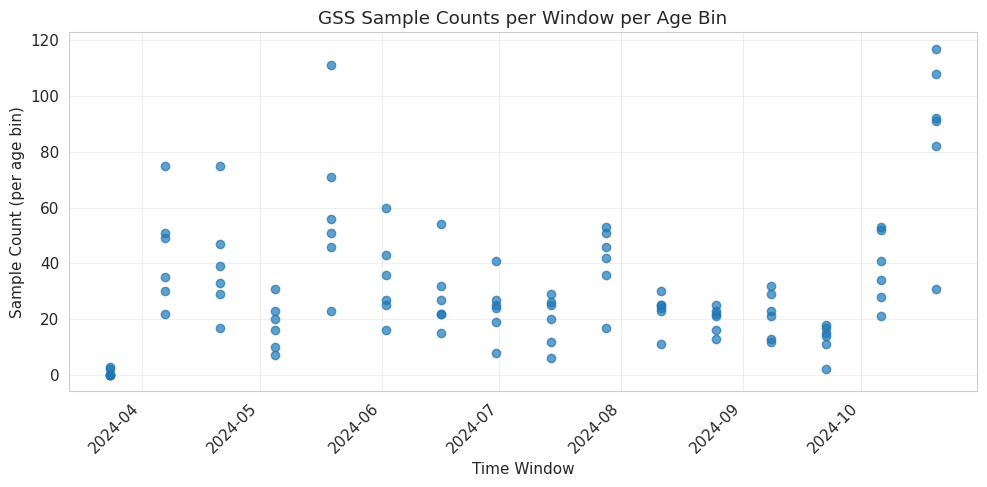

In [33]:
# Scatter plot: one dot per (window, age bin)
gss_age_window_counts['time_dt'] = pd.to_datetime(gss_age_window_counts['time_window_start'])
plt.figure(figsize=(10, 5))
plt.scatter(gss_age_window_counts['time_dt'], gss_age_window_counts['n'], alpha=0.7)
plt.title('GSS Sample Counts per Window per Age Bin')
plt.xlabel('Time Window')
plt.ylabel('Sample Count (per age bin)')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()



Plots will be saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant/gss_visualizations

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant/gss_visualizations/expected_value_trends_sex.png


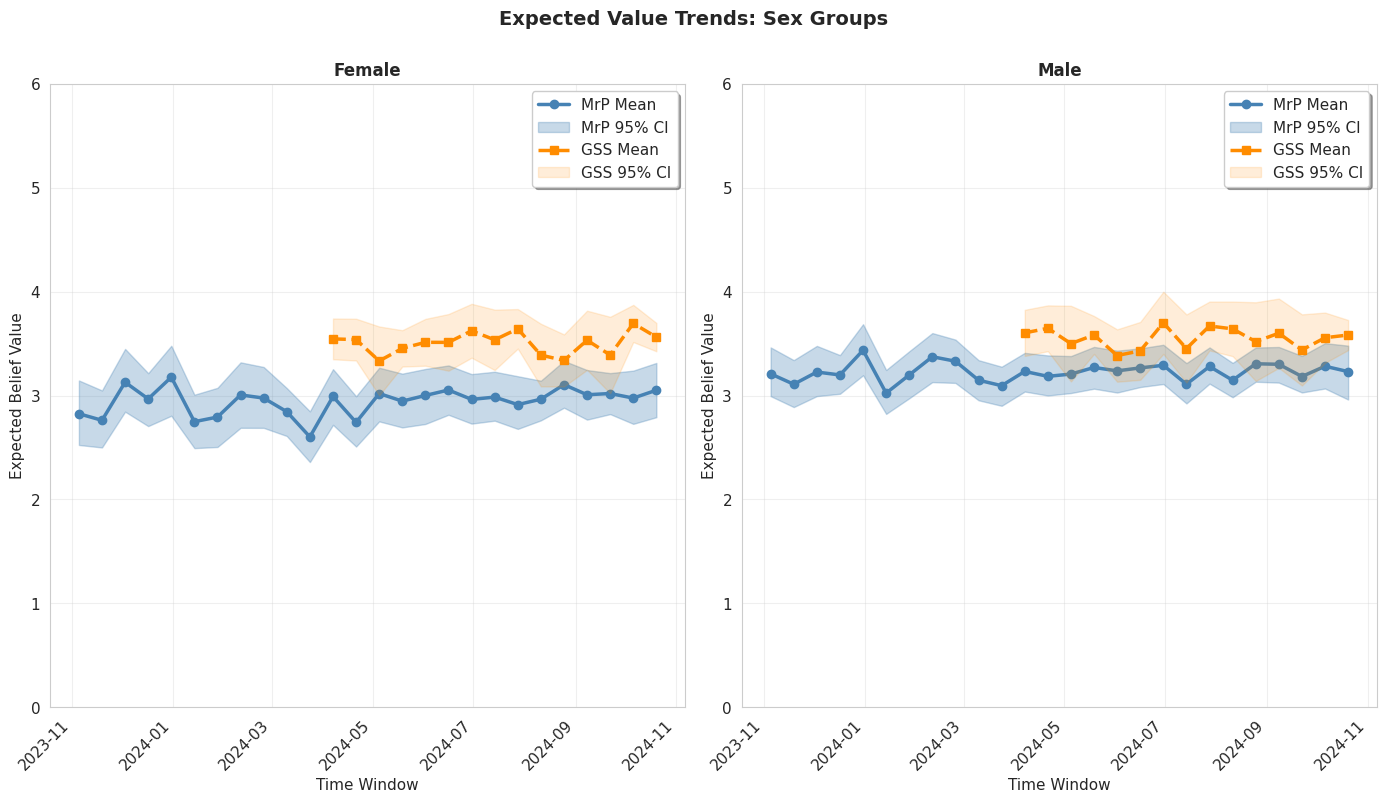

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant/gss_visualizations/expected_value_trends_age.png


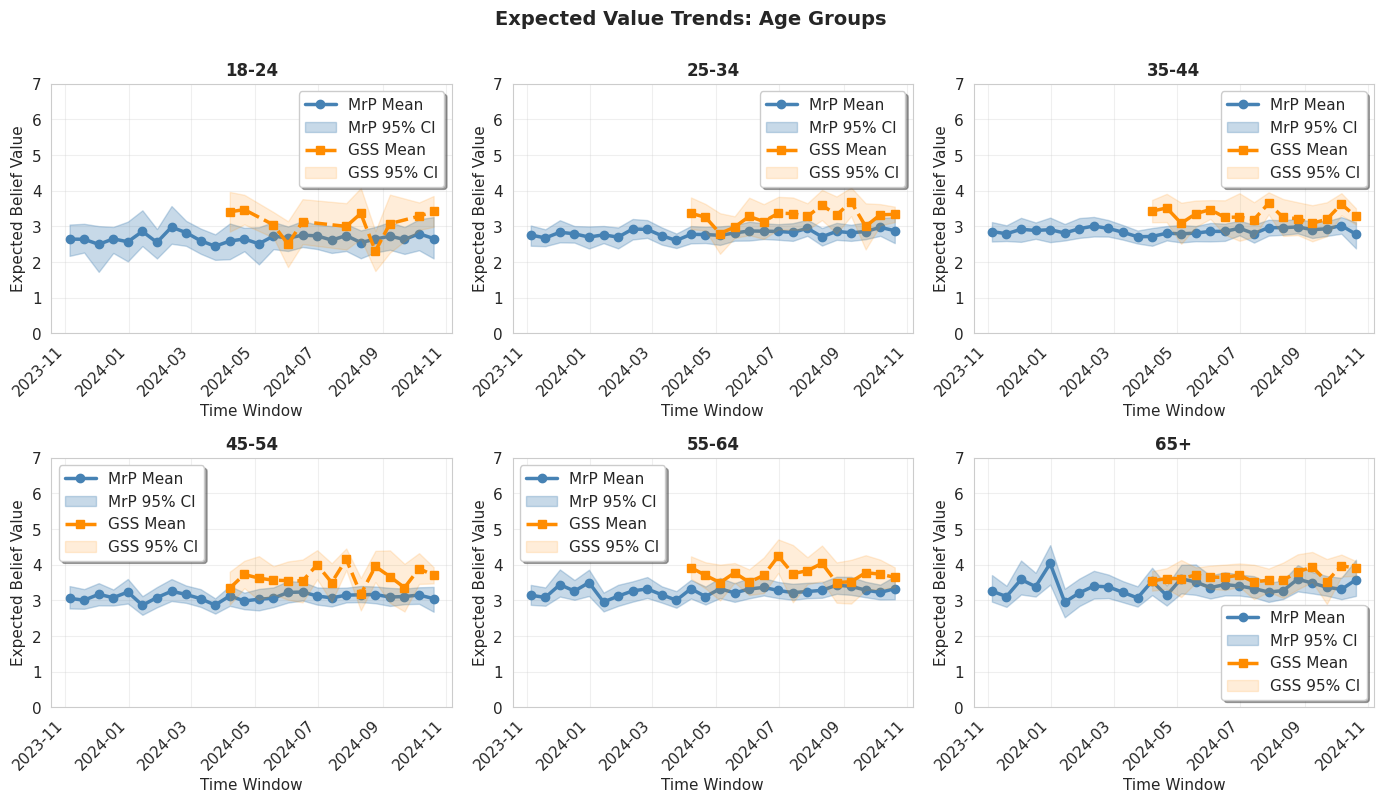

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant/gss_visualizations/expected_value_trends_vote.png


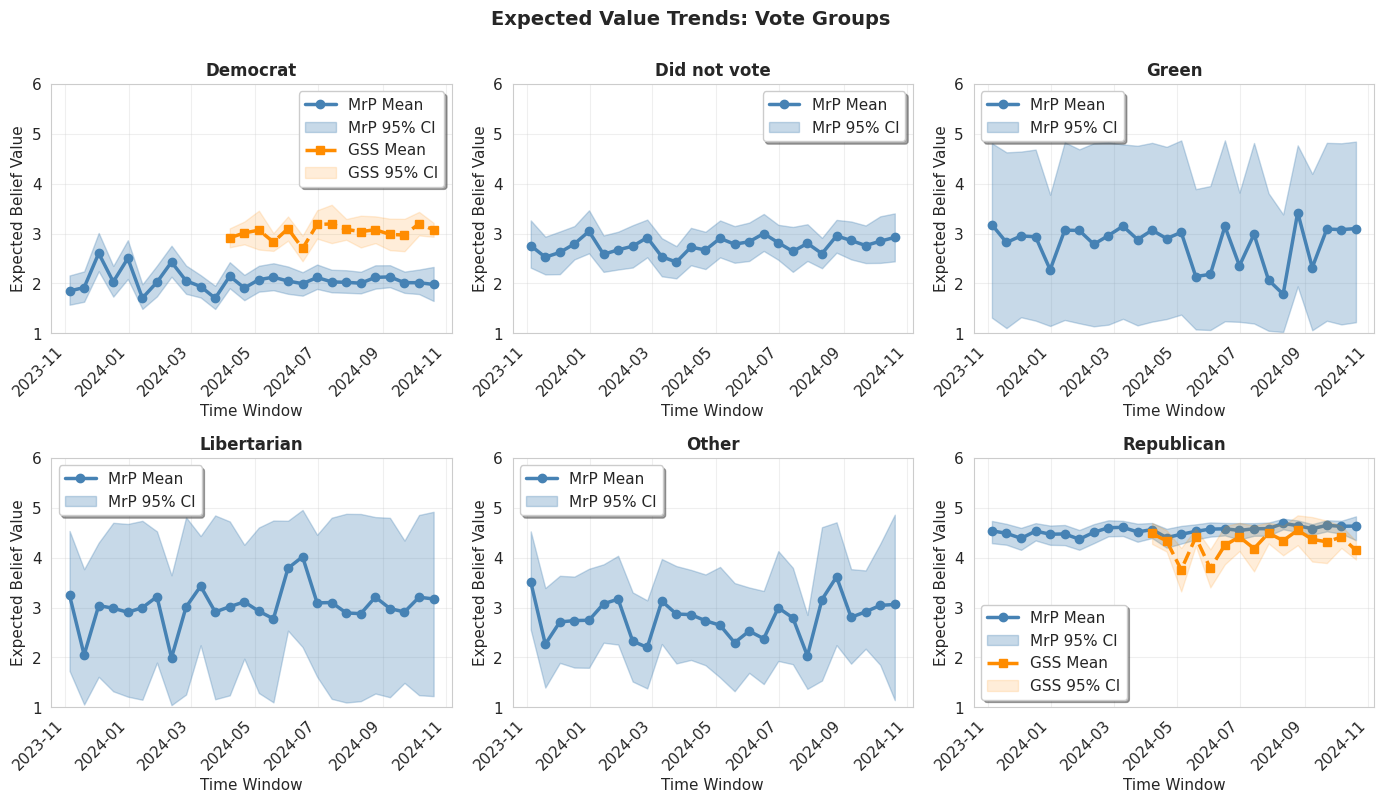

Plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant/gss_visualizations/expected_value_trends_income_selected.png


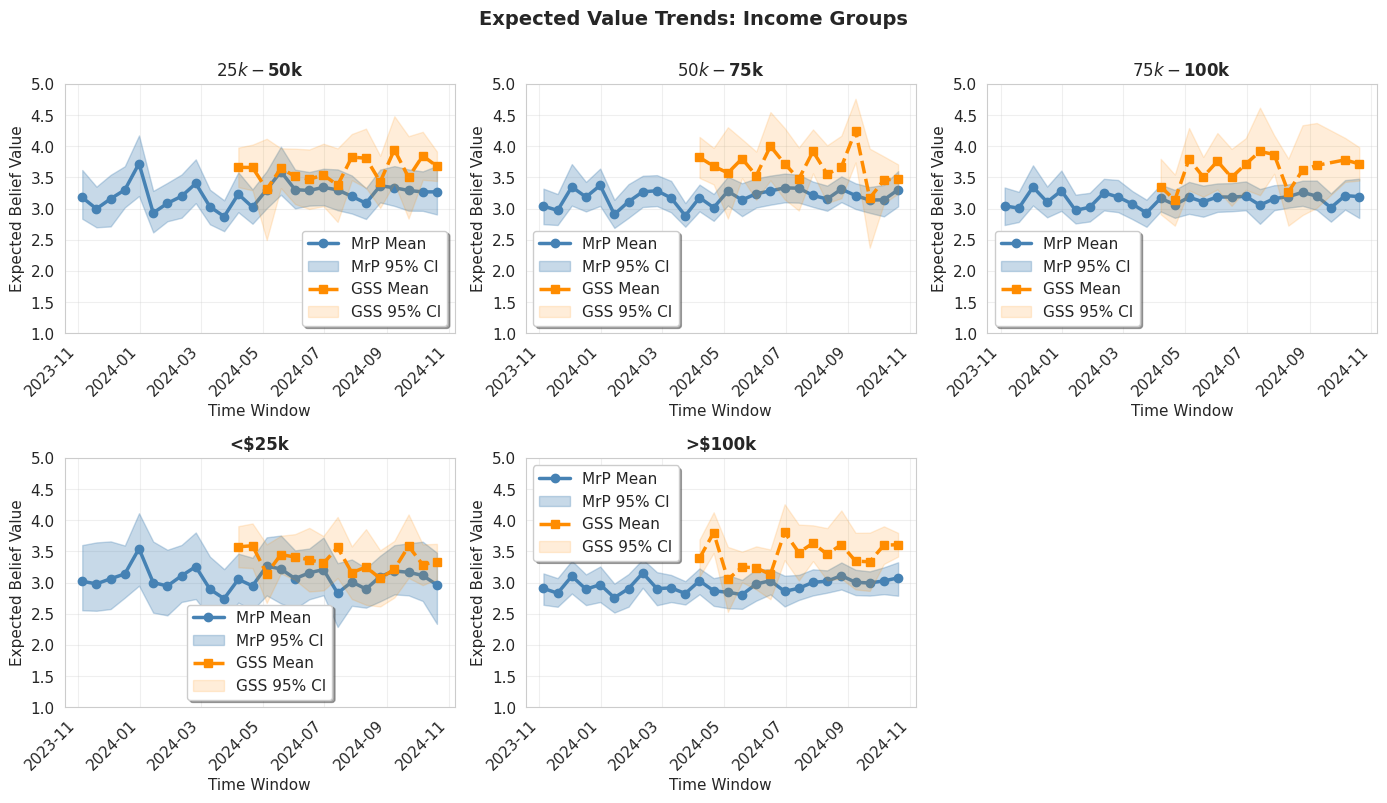


All plots saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant/gss_visualizations


In [46]:
# Create output directory for plots
plots_dir = f"{base_dir}/gss_visualizations"
os.makedirs(plots_dir, exist_ok=True)
print(f"Plots will be saved to: {plots_dir}\n")

# Plot expected value trends by sex
plot_expected_value_trends(
    base_dir, 
    belief_col, 
    group_name='sex',
    figsize=(14, 8),
    ncols=2,
    gss_timeseries=gss_ts_sex,
    save_path=f"{plots_dir}/expected_value_trends_sex.png"
)

# Plot expected value trends by age
plot_expected_value_trends(
    base_dir, 
    belief_col, 
    group_name='age',
    figsize=(14, 8),
    ncols=3,
    gss_timeseries=gss_ts_age,
    save_path=f"{plots_dir}/expected_value_trends_age.png"
)

# Plot expected value trends by vote
plot_expected_value_trends(
    base_dir, 
    belief_col, 
    group_name='vote',
    figsize=(14, 8),
    ncols=3,
    gss_timeseries=gss_ts_vote,
    save_path=f"{plots_dir}/expected_value_trends_vote.png"
)

# Plot expected value trends by income (selected groups)
plot_expected_value_trends(
    base_dir,
    belief_col,
    group_name='income',
    figsize=(14, 8),
    ncols=3,\
    gss_timeseries=gss_ts_income,
    save_path=f"{plots_dir}/expected_value_trends_income_selected.png"
)

print(f"\nAll plots saved to: {plots_dir}")

Comparison: MrP Predictions vs GSS Data

--- SEX ---
  RMSE: 0.5260, MAE: 0.4496, Corr: -0.2950

--- AGE ---
  RMSE: 0.5384, MAE: 0.4626, Corr: 0.5744

--- INCOME ---
  RMSE: 0.5780, MAE: 0.4426, Corr: 0.0277

--- VOTE ---
  RMSE: 0.7303, MAE: 0.6213, Corr: 0.9425

All comparison plots saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant/gss_visualizations/comparison_all_groups_overall.png


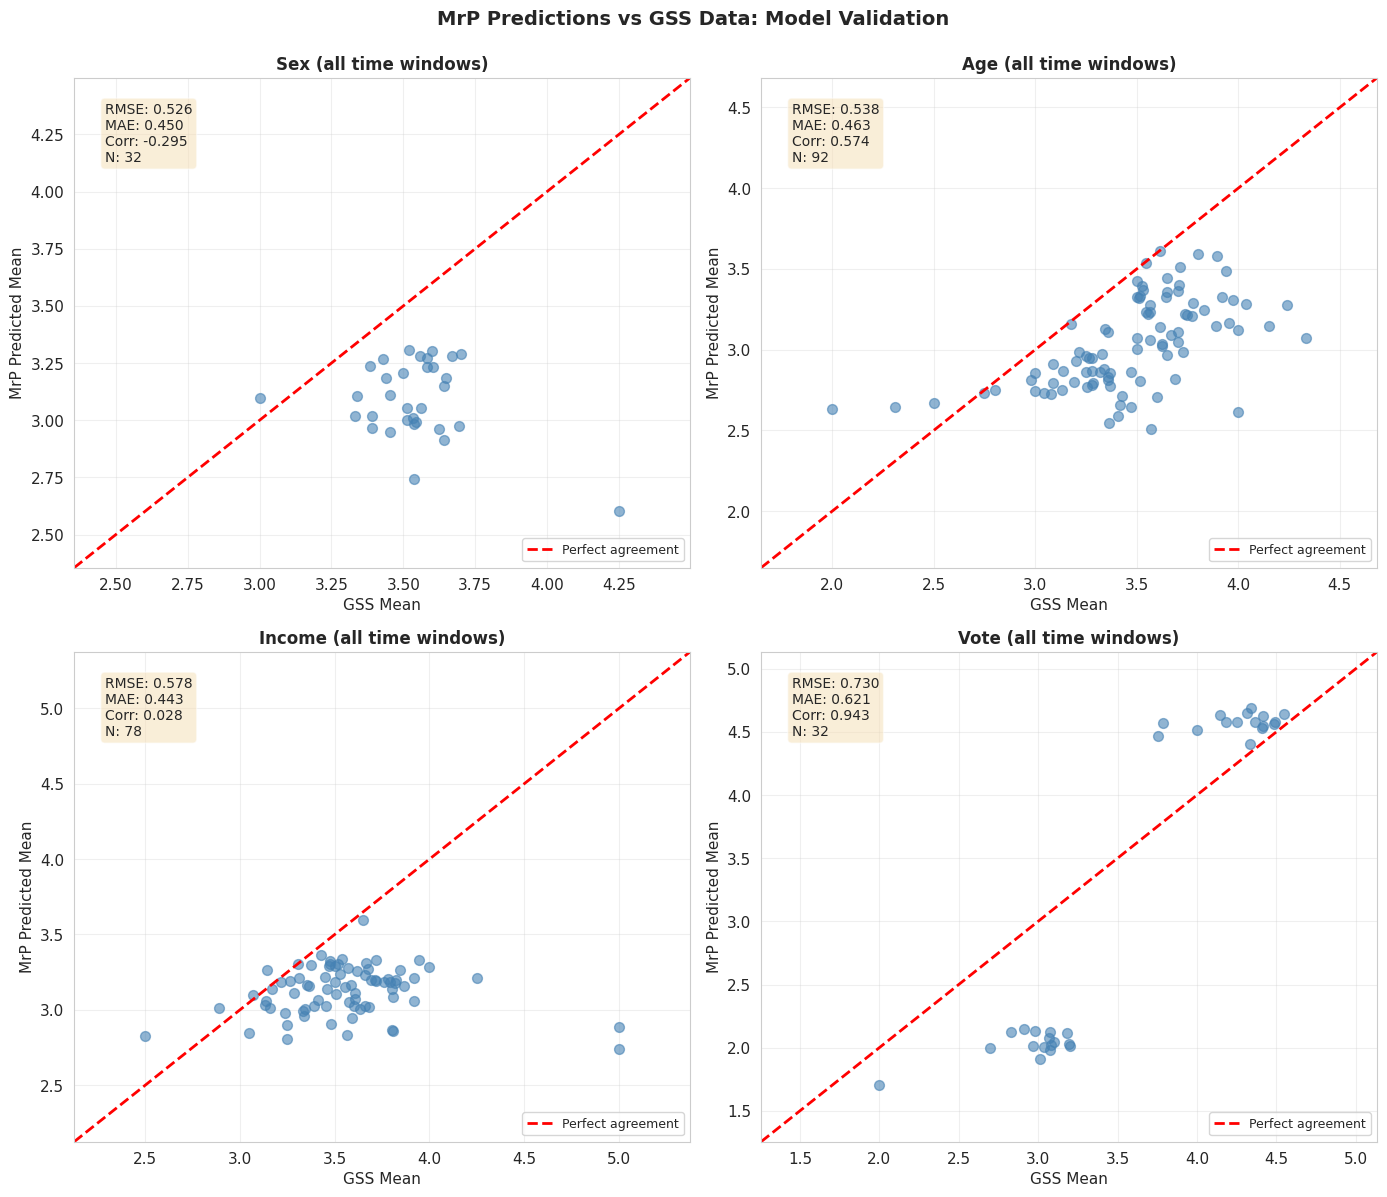

In [51]:
# Comparison of MrP predictions vs GSS data

def prepare_comparison_data(base_dir, belief_col, group_name, gss_timeseries):
    """
    Merge MrP predictions with GSS data for comparison.
    Returns combined dataframe with predicted and observed values.
    """
    # Load all predictions
    time_window_dirs = [d for d in os.listdir(base_dir) if d.startswith(belief_col)]
    time_windows = sorted([d.replace(f"{belief_col}_", "").replace("_stan_output", "") 
                           for d in time_window_dirs])
    
    all_preds = []
    for window in time_windows:
        pred_file = f"{base_dir}/{belief_col}_{window}_stan_output/group_{group_name}_predictions.csv"
        if os.path.exists(pred_file):
            preds = pd.read_csv(pred_file)
            preds['time_window_start'] = window
            all_preds.append(preds)
    
    mrp_data = pd.concat(all_preds, ignore_index=True)
    
    # Determine group column name for MrP (numeric index)
    mrp_group_col = f"{group_name}_idx"
    
    # Rename for clarity
    mrp_data = mrp_data.rename(columns={'pred_mean': 'mrp_mean'})
    gss_data = gss_timeseries.copy()
    gss_data = gss_data.rename(columns={'mean': 'gss_mean'})
    
    # Remove NaN values from GSS data before mapping
    gss_data = gss_data.dropna(subset=[group_name])
    
    # Convert GSS group column to numeric indices to match MrP
    # Create reverse mapping from group names to indices
    if mrp_group_col in label_mappings:
        reverse_map = {v: k for k, v in label_mappings[mrp_group_col].items()}
        gss_data[group_name] = gss_data[group_name].map(reverse_map)
        # Remove rows where mapping failed (resulted in NaN)
        gss_data = gss_data.dropna(subset=[group_name])
        gss_data[group_name] = gss_data[group_name].astype('int64')
    
    # Merge on numeric group index and time window
    comparison = mrp_data[[mrp_group_col, 'time_window_start', 'mrp_mean']].merge(
        gss_data[[group_name, 'time_window_start', 'gss_mean', 'n']],
        left_on=[mrp_group_col, 'time_window_start'],
        right_on=[group_name, 'time_window_start'],
        how='inner'
    )
    
    # Remove any remaining NaN values in numeric columns
    comparison = comparison.dropna(subset=['mrp_mean', 'gss_mean'])
    
    return comparison

def plot_comparison_scatter_on_ax(ax, comparison_df, title=""):
    """Plot MrP vs GSS on provided axis with y=x reference line."""
    # Check for empty or NaN data
    if len(comparison_df) == 0 or comparison_df[['mrp_mean', 'gss_mean']].isna().all().any():
        ax.text(0.5, 0.5, 'No valid data', ha='center', va='center', transform=ax.transAxes)
        return None
    
    # Get data range, excluding NaN, with padding
    all_vals = np.concatenate([
        comparison_df['mrp_mean'].dropna().values, 
        comparison_df['gss_mean'].dropna().values
    ])
    
    if len(all_vals) == 0:
        ax.text(0.5, 0.5, 'All values are NaN', ha='center', va='center', transform=ax.transAxes)
        return None
    
    val_min, val_max = all_vals.min(), all_vals.max()
    val_range = val_max - val_min
    # Add 15% padding on each side
    padding = val_range * 0.15
    axis_min = val_min - padding
    axis_max = val_max + padding
    
    # Scatter plot
    ax.scatter(comparison_df['gss_mean'], comparison_df['mrp_mean'], 
              alpha=0.6, s=50, color='steelblue')
    
    # y=x reference line
    ax.plot([axis_min, axis_max], [axis_min, axis_max], 'r--', lw=2, label='Perfect agreement')
    
    ax.set_xlim([axis_min, axis_max])
    ax.set_ylim([axis_min, axis_max])
    ax.set_xlabel('GSS Mean', fontsize=11)
    ax.set_ylabel('MrP Predicted Mean', fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)
    
    # Add accuracy metrics
    rmse = np.sqrt(np.mean((comparison_df['mrp_mean'] - comparison_df['gss_mean'])**2))
    mae = np.mean(np.abs(comparison_df['mrp_mean'] - comparison_df['gss_mean']))
    corr = comparison_df['mrp_mean'].corr(comparison_df['gss_mean'])
    
    textstr = f'RMSE: {rmse:.3f}\nMAE: {mae:.3f}\nCorr: {corr:.3f}\nN: {len(comparison_df)}'
    ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=10,
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    return {'rmse': rmse, 'mae': mae, 'corr': corr, 'n': len(comparison_df)}

# Overall comparison per demographic (across all time windows)
print("=" * 60)
print("Comparison: MrP Predictions vs GSS Data")
print("=" * 60)

# Create a 2x2 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

all_metrics = {}
group_list = [('sex', gss_ts_sex), ('age', gss_ts_age), 
              ('income', gss_ts_income), ('vote', gss_ts_vote)]

for idx, (group_name, gss_ts) in enumerate(group_list):
    print(f"\n--- {group_name.upper()} ---")
    try:
        comparison = prepare_comparison_data(base_dir, belief_col, group_name, gss_ts)
        if len(comparison) > 0:
            metrics = plot_comparison_scatter_on_ax(
                axes[idx],
                comparison, 
                title=f'{group_name.capitalize()} (all time windows)'
            )
            if metrics:
                all_metrics[group_name] = metrics
                print(f"  RMSE: {metrics['rmse']:.4f}, MAE: {metrics['mae']:.4f}, Corr: {metrics['corr']:.4f}")
        else:
            axes[idx].text(0.5, 0.5, f'No matching data for {group_name}', 
                          ha='center', va='center', transform=axes[idx].transAxes)
            print(f"  No matching data found for {group_name}")
    except Exception as e:
        axes[idx].text(0.5, 0.5, f'Error: {str(e)}', 
                      ha='center', va='center', transform=axes[idx].transAxes, fontsize=9)
        print(f"  Error processing {group_name}: {str(e)}")

plt.suptitle('MrP Predictions vs GSS Data: Model Validation', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig(f"{plots_dir}/comparison_all_groups_overall.png", dpi=300, bbox_inches='tight')
print(f"\nAll comparison plots saved to: {plots_dir}/comparison_all_groups_overall.png")
plt.show()


Combined Comparison: All Groups & Time Windows

Combined comparison plot saved to: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant/gss_visualizations/comparison_all_combined.png
Overall RMSE: 0.5797, MAE: 0.4759, Corr: 0.6536
Total datapoints: 234


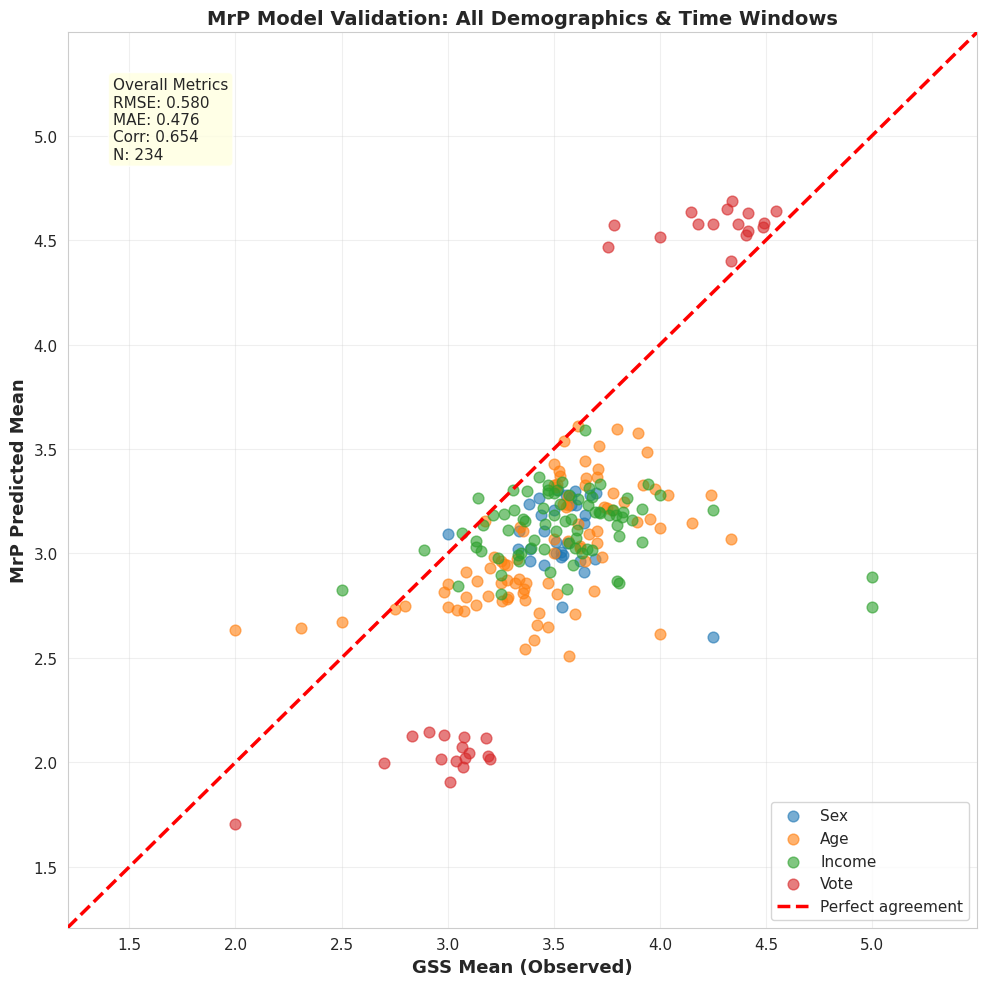

In [53]:

# Combined comparison: All groups and time windows on single y=x plot
print("\n" + "=" * 60)
print("Combined Comparison: All Groups & Time Windows")
print("=" * 60)

# Prepare comparison data for all groups
all_comparison_data = []
group_colors = {'sex': '#1f77b4', 'age': '#ff7f0e', 'income': '#2ca02c', 'vote': '#d62728'}

for group_name, gss_ts in [('sex', gss_ts_sex), ('age', gss_ts_age), 
                            ('income', gss_ts_income), ('vote', gss_ts_vote)]:
    try:
        comparison = prepare_comparison_data(base_dir, belief_col, group_name, gss_ts)
        if len(comparison) > 0:
            comparison['group'] = group_name
            all_comparison_data.append(comparison)
    except Exception as e:
        print(f"  Warning: Could not process {group_name}: {str(e)}")

# Combine all data
combined_data = pd.concat(all_comparison_data, ignore_index=True)
combined_data = combined_data.dropna(subset=['mrp_mean', 'gss_mean'])

if len(combined_data) > 0:
    # Create single plot
    fig, ax = plt.subplots(figsize=(10, 10))
    
    # Get data range with padding
    all_vals = np.concatenate([combined_data['mrp_mean'].values, combined_data['gss_mean'].values])
    val_min, val_max = all_vals.min(), all_vals.max()
    val_range = val_max - val_min
    padding = val_range * 0.15
    axis_min = val_min - padding
    axis_max = val_max + padding
    
    # Plot each group with different color
    for group_name in combined_data['group'].unique():
        group_data = combined_data[combined_data['group'] == group_name]
        ax.scatter(group_data['gss_mean'], group_data['mrp_mean'], 
                  alpha=0.6, s=60, label=group_name.capitalize(),
                  color=group_colors[group_name])
    
    # y=x reference line
    ax.plot([axis_min, axis_max], [axis_min, axis_max], 'r--', lw=2.5, label='Perfect agreement', zorder=5)
    
    ax.set_xlim([axis_min, axis_max])
    ax.set_ylim([axis_min, axis_max])
    ax.set_xlabel('GSS Mean (Observed)', fontsize=13, fontweight='bold')
    ax.set_ylabel('MrP Predicted Mean', fontsize=13, fontweight='bold')
    ax.set_title('MrP Model Validation: All Demographics & Time Windows', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=11, loc='lower right')
    
    # Calculate overall metrics
    rmse = np.sqrt(np.mean((combined_data['mrp_mean'] - combined_data['gss_mean'])**2))
    mae = np.mean(np.abs(combined_data['mrp_mean'] - combined_data['gss_mean']))
    corr = combined_data['mrp_mean'].corr(combined_data['gss_mean'])
    
    textstr = f'Overall Metrics\nRMSE: {rmse:.3f}\nMAE: {mae:.3f}\nCorr: {corr:.3f}\nN: {len(combined_data)}'
    ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=11,
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
    
    plt.tight_layout()
    plt.savefig(f"{plots_dir}/comparison_all_combined.png", dpi=300, bbox_inches='tight')
    print(f"\nCombined comparison plot saved to: {plots_dir}/comparison_all_combined.png")
    print(f"Overall RMSE: {rmse:.4f}, MAE: {mae:.4f}, Corr: {corr:.4f}")
    print(f"Total datapoints: {len(combined_data)}")
    plt.show()
else:
    print("No data available for combined comparison")



Per-Group Subcategory Comparison: MrP vs GSS

--- SEX ---
  Saved: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant/gss_visualizations/comparison_sex_subcategories.png


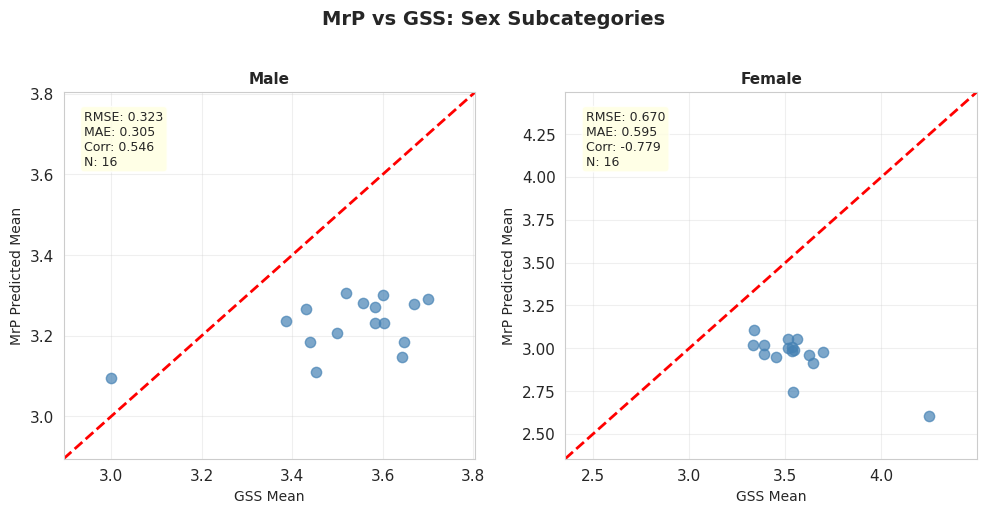


--- AGE ---
  Saved: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant/gss_visualizations/comparison_age_subcategories.png


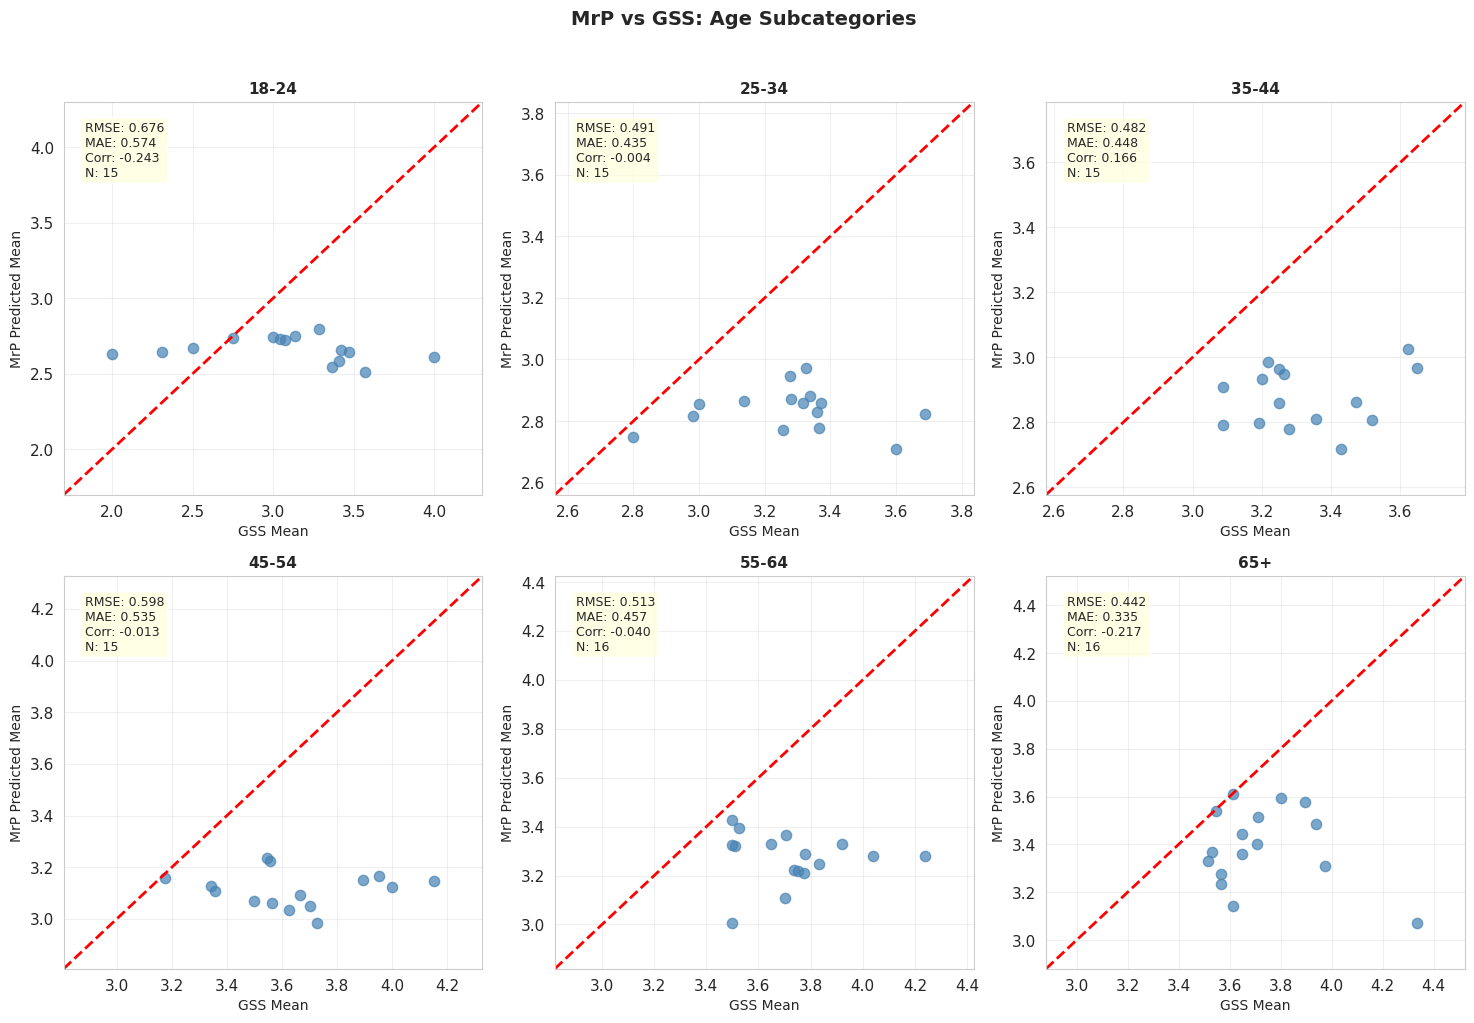


--- INCOME ---
  Saved: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant/gss_visualizations/comparison_income_subcategories.png


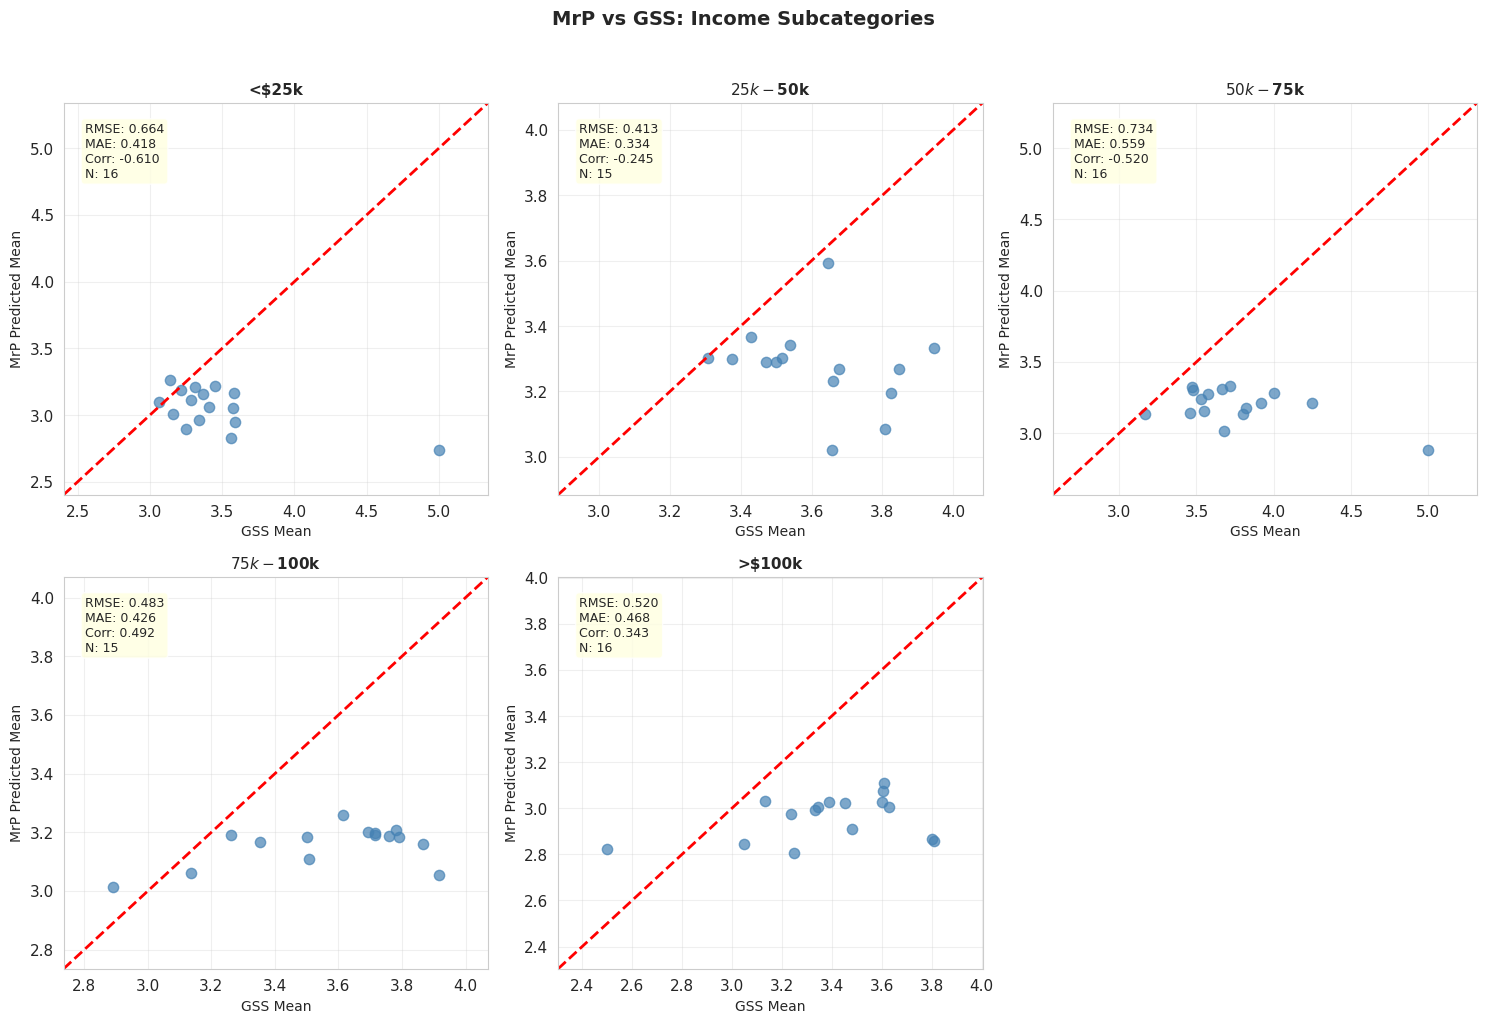


--- VOTE ---
  Saved: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Order_Immigrant/gss_visualizations/comparison_vote_subcategories.png


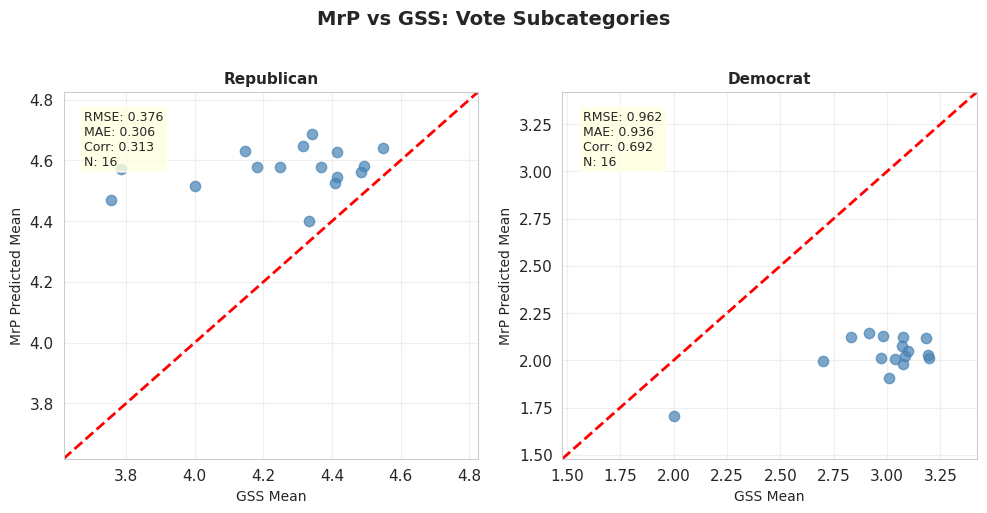

In [54]:

# Per-group category-level comparison: y=x plots for each subcategory
print("\n" + "=" * 60)
print("Per-Group Subcategory Comparison: MrP vs GSS")
print("=" * 60)

# Helper: map numeric indices to labels for subplot titles
label_maps = {k.replace('_idx', ''): v for k, v in label_mappings.items()}

# Build a combined dataframe for each demographic, then plot each subcategory
for group_name, gss_ts in [('sex', gss_ts_sex), ('age', gss_ts_age), 
                            ('income', gss_ts_income), ('vote', gss_ts_vote)]:
    print(f"\n--- {group_name.upper()} ---")
    try:
        comparison = prepare_comparison_data(base_dir, belief_col, group_name, gss_ts)
        if len(comparison) == 0:
            print(f"  No matching data found for {group_name}")
            continue
        
        # Identify numeric group column in merged comparison
        mrp_group_col = f"{group_name}_idx"
        if mrp_group_col not in comparison.columns:
            print(f"  Missing column {mrp_group_col} in comparison data")
            continue
        
        # List subcategory ids present in data
        subgroup_ids = sorted(comparison[mrp_group_col].dropna().unique())
        n_groups = len(subgroup_ids)
        if n_groups == 0:
            print(f"  No subcategories found for {group_name}")
            continue
        
        # Layout
        ncols = 3 if n_groups > 3 else n_groups
        nrows = int(np.ceil(n_groups / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows), squeeze=False)
        axes = axes.flatten()
        
        # Label map for titles
        group_label_map = label_maps.get(group_name, {})
        
        for idx, sub_id in enumerate(subgroup_ids):
            ax = axes[idx]
            sub_data = comparison[comparison[mrp_group_col] == sub_id].copy()
            sub_data = sub_data.dropna(subset=['mrp_mean', 'gss_mean'])
            
            if len(sub_data) == 0:
                ax.text(0.5, 0.5, 'No valid data', ha='center', va='center', transform=ax.transAxes)
                ax.set_axis_off()
                continue
            
            # Axis range with padding
            all_vals = np.concatenate([sub_data['mrp_mean'].values, sub_data['gss_mean'].values])
            val_min, val_max = all_vals.min(), all_vals.max()
            val_range = val_max - val_min
            padding = val_range * 0.15 if val_range > 0 else 0.5
            axis_min = val_min - padding
            axis_max = val_max + padding
            
            # Scatter
            ax.scatter(sub_data['gss_mean'], sub_data['mrp_mean'], alpha=0.7, s=55, color='steelblue')
            ax.plot([axis_min, axis_max], [axis_min, axis_max], 'r--', lw=2)
            ax.set_xlim([axis_min, axis_max])
            ax.set_ylim([axis_min, axis_max])
            ax.set_xlabel('GSS Mean', fontsize=10)
            ax.set_ylabel('MrP Predicted Mean', fontsize=10)
            
            # Title
            label = group_label_map.get(sub_id, str(sub_id))
            ax.set_title(f"{label}", fontsize=11, fontweight='bold')
            ax.grid(True, alpha=0.3)
            
            # Metrics per subcategory
            rmse = np.sqrt(np.mean((sub_data['mrp_mean'] - sub_data['gss_mean'])**2))
            mae = np.mean(np.abs(sub_data['mrp_mean'] - sub_data['gss_mean']))
            corr = sub_data['mrp_mean'].corr(sub_data['gss_mean'])
            textstr = f'RMSE: {rmse:.3f}\nMAE: {mae:.3f}\nCorr: {corr:.3f}\nN: {len(sub_data)}'
            ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=9,
                    verticalalignment='top', bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
        
        # Hide unused axes
        for j in range(n_groups, len(axes)):
            axes[j].set_axis_off()
        
        plt.suptitle(f'MrP vs GSS: {group_name.capitalize()} Subcategories', fontsize=14, fontweight='bold', y=1.02)
        plt.tight_layout()
        out_path = f"{plots_dir}/comparison_{group_name}_subcategories.png"
        plt.savefig(out_path, dpi=300, bbox_inches='tight')
        print(f"  Saved: {out_path}")
        plt.show()
    except Exception as e:
        print(f"  Error processing {group_name}: {str(e)}")
